In [1]:
# Experiment 03 — Grover Search Using Two Qubits

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

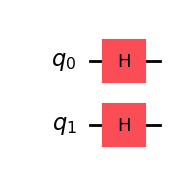

Initial Probabilities:
{np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}


In [3]:
# Create a circuit with two qubits
qc = QuantumCircuit(2)

# Apply Hadamard gates
qc.h([0, 1])

# Display the circuit
display(qc.draw("mpl"))

# Check the initial probabilities
state = Statevector.from_instruction(qc)

print("Initial Probabilities:")
print(state.probabilities_dict())

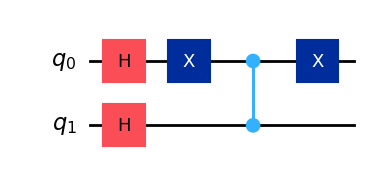

Statevector after Oracle:
[ 0.5+0.j  0.5+0.j -0.5+0.j  0.5+0.j]


In [4]:
# Mark the target state |10>
qc.x(0)
qc.cz(0, 1)
qc.x(0)

# Display the circuit
display(qc.draw("mpl"))

# Check the state after the oracle
oracle_state = Statevector.from_instruction(qc)

print("Statevector after Oracle:")
print(np.round(oracle_state.data, 4))

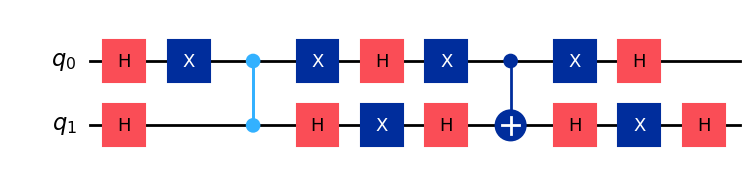

In [5]:
# Apply the diffusion operator
qc.h([0, 1])
qc.x([0, 1])

qc.h(1)
qc.cx(0, 1)
qc.h(1)

qc.x([0, 1])
qc.h([0, 1])

# Display the complete circuit
display(qc.draw("mpl"))

In [6]:
# Calculate the final quantum state
final_state = Statevector.from_instruction(qc)

print("Final Statevector:")
print(np.round(final_state.data, 4))

print("\nFinal Probabilities:")
print({
    str(k): round(float(v), 4)
    for k, v in final_state.probabilities_dict().items()
})

Final Statevector:
[ 0.+0.j  0.+0.j -1.+0.j  0.+0.j]

Final Probabilities:
{'00': 0.0, '01': 0.0, '10': 1.0, '11': 0.0}


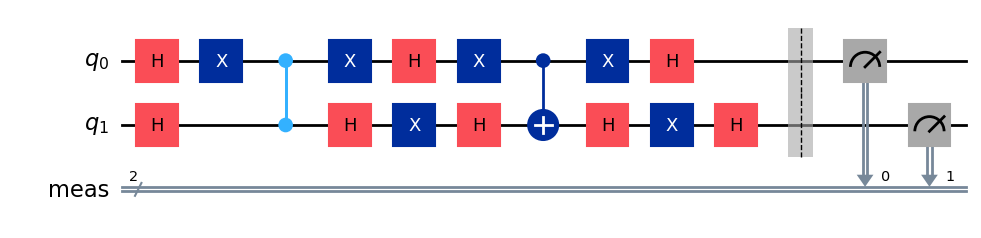

Measurement Counts: {'10': 1024}


In [7]:
# Add measurements to both qubits
qc_measure = qc.copy()
qc_measure.measure_all()

# Display the measurement circuit
display(qc_measure.draw("mpl"))

# Run the circuit 1024 times
simulator = AerSimulator()

result = simulator.run(
    transpile(qc_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

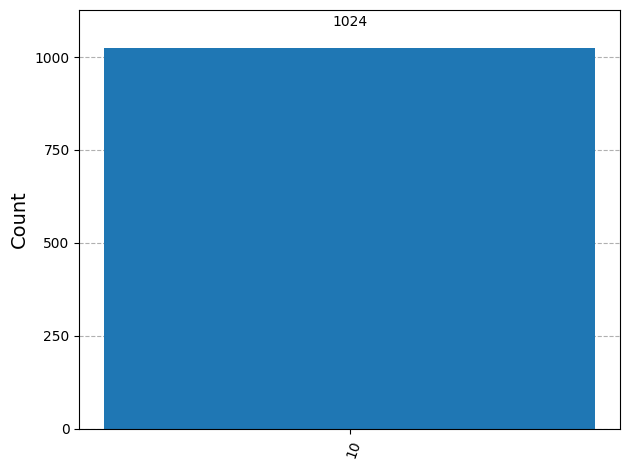

Target State: 10
Measured State: 10
Success Probability: 1.0


In [8]:
# Plot the measurement results
display(plot_histogram(counts))

# Find the most frequently measured state
measured_state = max(counts, key=counts.get)

print("Target State:", "10")
print("Measured State:", measured_state)
print("Success Probability:", counts.get("10", 0) / sum(counts.values()))